In [1]:
!git clone https://github.com/iMoonLab/yolov13.git
%cd yolov13
!pip install -r requirements.txt
!pip install -e .

fatal: destination path 'yolov13' already exists and is not an empty directory.
/content/yolov13
ERROR: flash_attn-2.7.3+cu11torch2.2cxx11abiFALSE-cp311-cp311-linux_x86_64.whl is not a supported wheel on this platform.
Obtaining file:///content/yolov13
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Created wheel for ultralytics: filename=ultralytics-8.3.63-0.editable-py3-none-any.whl size=20481 sha256=f1fa5e28858f53b9baac633c71d06ca3e9fdce4be2e06647b0e7067efcd5e323
  Stored in directory: /tmp/pip-ephem-wheel-cache-4mu_p7eh/wheels/52/98/bf/402e0bccd80ed093c2cf8857ceab45db5da5935b4ad0fb44c2
Successfully built ultralytics
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.3.63
    Uninstalling ultralytics-8.3.63:
      Successfully unin

In [2]:
# ── Patch tasks.py BEFORE ultralytics is imported ──────────────────────────
tasks_path = '/content/yolov13/ultralytics/nn/tasks.py'

with open(tasks_path, 'r') as f:
    content = f.read()

# 8 spasi untuk elif (dalam for-loop parse_model), 12 spasi untuk body
cbam_block    = '        elif m is CBAM:\n            c2 = ch[f]\n            args = [c2]\n'
insert_before = '        elif m is FullPAD_Tunnel:'

if 'elif m is CBAM:' not in content:
    assert insert_before in content, "Anchor tidak ditemukan di tasks.py"
    content = content.replace(insert_before, cbam_block + insert_before)
    with open(tasks_path, 'w') as f:
        f.write(content)
    print("✅ tasks.py patched")
else:
    print("⚠️  tasks.py sudah pernah di-patch, skip")

⚠️  tasks.py sudah pernah di-patch, skip


In [3]:
# try:
#     from ultralytics import YOLO
# except:
#     !pip install -q ultralytics
#     from ultralytics import YOLO

import torch
import yaml
import os
import shutil

# !pip install ultralytics
from ultralytics import YOLO

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {device}')
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))
    !nvidia-smi


FlashAttention is not available on this device. Using scaled_dot_product_attention instead.
Device: cuda
NVIDIA RTX PRO 6000 Blackwell Server Edition
Sat Jun 20 07:35:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   29C    P0             47W /  600W |       3MiB /  97887MiB |      0%      

In [4]:
%cd /content

/content


In [5]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

HOME = "/content"

print(HOME)
project_basepath = f'{HOME}/drive/MyDrive/Project/Fire And Smoke'
dataset_basepath = os.path.join(project_basepath, 'datasets')

Mounted at /content/drive
/content


# Load Dataset and Create data.yaml

In [6]:
# 'fire-smoke', 'fire-smoke_he', 'fire-smoke_cs', 'fire-smoke_clahe-cs',
# 'fire-smoke_clahe-dgc-cs',
dataset_name = 'fire-smoke'

# unzip the dataset
zip_file = os.path.join(dataset_basepath, f'{dataset_name}.zip')
!unzip -o "{zip_file}" -d "{HOME}/{dataset_name}"

# create data.yaml
data = {
    "train": os.path.join(HOME, f'{dataset_name}/train/images'),
    "val": os.path.join(HOME, f'{dataset_name}/valid/images'),
    "test": os.path.join(HOME, f'{dataset_name}/test/images'),
    "nc": 2,
    "names": ["Smoke", "Fire"]
}

path = os.path.join(HOME, dataset_name)
file_name = "data.yaml"
with open(os.path.join(path, file_name), "w") as file:
    yaml.dump(data, file, default_flow_style=False)

print(f"File YAML created successfully: {os.path.join(path, file_name)}")


Output streaming akan dipotong hingga 5000 baris terakhir.
  inflating: /content/fire-smoke/valid/labels/WEBFire142_jpg.rf.cceea8ef42942fcaa1fad56f0e75f5ac.txt  
  inflating: /content/fire-smoke/valid/labels/MirrorWEBFire1590_jpg.rf.cb51b1ba579b403d2b1543c61debacb0.txt  
  inflating: /content/fire-smoke/valid/labels/WEBSmoke1702_jpg.rf.e7359f70fa1cdae63dc344cae6dd182c.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire1708_jpg.rf.0ad08788e19211cfe0b7d91352feda58.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire1001_jpg.rf.3da1ab0d16e7ed6f08c27ad4f65ae880.txt  
  inflating: /content/fire-smoke/valid/labels/MirrorWEBSmoke2808_jpg.rf.26c01e7813277b297f8dab0cba59efd5.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire285_jpg.rf.51a41425bbbc39472a79d66f5e98c704.txt  
  inflating: /content/fire-smoke/valid/labels/WEBSmoke813_jpg.rf.5f2c514a2a1d0fd80f585d1ced73e5d0.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBSmoke137_jpg.rf.5cfadf40602c

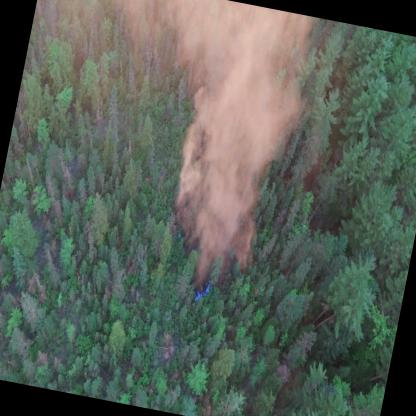

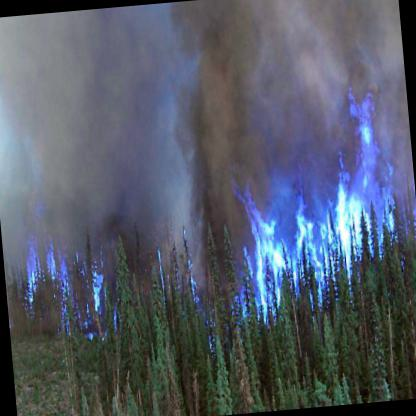

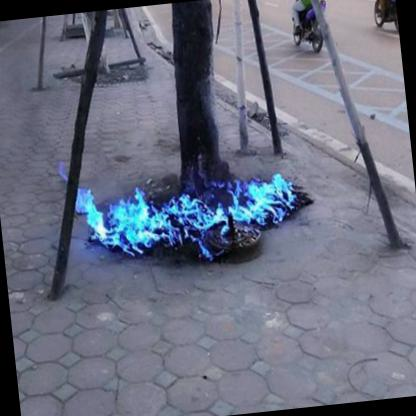

In [7]:
import cv2
from PIL import Image

img_list = ['forest1_jpg.rf.18a2371bce9b6426a577fee70da96d29.jpg', 'forest3_jpg.rf.d0ea44f5d16d773891c17044c62c1d84.jpg', 'forest2_jpg.rf.a9f9ccad1ebc5877c0f9bcd6a8eb1e5e.jpg']
for i in img_list:
  display(Image.fromarray(cv2.imread(f'/content/fire-smoke/train/images/{i}')))

# Setup YOLO Model

In [8]:
import os

for root, dirs, files in os.walk("/content/fire-smoke"):
    print(root, dirs, len(files))

/content/fire-smoke ['test', 'train', 'valid'] 1
/content/fire-smoke/test ['images', 'labels'] 0
/content/fire-smoke/test/images [] 1059
/content/fire-smoke/test/labels [] 1059
/content/fire-smoke/train ['images', 'labels'] 1
/content/fire-smoke/train/images [] 8494
/content/fire-smoke/train/labels [] 8494
/content/fire-smoke/valid ['images', 'labels'] 1
/content/fire-smoke/valid/images [] 2114
/content/fire-smoke/valid/labels [] 2114


In [9]:
import sys, os, shutil, torch
import gc  # ✅ ADD: Garbage collector

HOME = "/content"
sys.path.insert(0, HOME)

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

SRC = "/content/drive/MyDrive/Project/Fire And Smoke"
DATA_PATH = os.path.join(HOME, "fire-smoke", "data.yaml")
DATASET_NAME = os.path.basename(os.path.dirname(DATA_PATH))
BASE_DIR = os.path.join(SRC, "runs")

# Copy CBAM files to /content/
for f in ["cbam.py", "yolov13s-cbam-backbone.yaml", "yolov13s-cbam-neck.yaml", "yolov13s-cbam-head.yaml"]:
    shutil.copy(os.path.join(SRC, f), os.path.join(HOME, f))
print("CBAM files copied")

# Register CBAM module
from cbam import CBAM
import ultralytics.nn.modules as ul_m; ul_m.CBAM = CBAM
import ultralytics.nn.tasks as ul_t; ul_t.CBAM = CBAM
import inspect, ultralytics.nn.tasks as _t
assert 'elif m is CBAM' in inspect.getsource(_t.parse_model), \
    "❌ patch not active — did you run the patch cell before Cell 1?"
print("✅ CBAM registered & patch verified")

# ═══════════════════════════════════════════════════════════════
# Memory Management Function ✅ NEW
# ═══════════════════════════════════════════════════════════════
def clear_memory():
    """Clear GPU and CPU memory to prevent leaks"""
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    print("🧹 Memory cleared")

# ═══════════════════════════════════════════════════════════════
# Hyperparameters
# ═══════════════════════════════════════════════════════════════
EPOCHS = 300
BATCH = 96
IMSZ = 640
OPTIM = "SGD"
LR0 = 0.01
MOMENTUM = 0.937
WEIGHT_DECAY = 0.0005
WARMUP_EPOCHS = 3
IOU = 0.5
PATIENCE = 100
DEVICE = 0 if torch.cuda.is_available() else "cpu"
SEED = 5

# ═══════════════════════════════════════════════════════════════
# Augmentation Parameters - Aggressive (State-of-the-Art)
# ═══════════════════════════════════════════════════════════════
AUG_PARAMS = {
    'hsv_h': 0.02,         # Fire color variation
    'hsv_s': 0.7,          # Saturation variation
    'hsv_v': 0.4,          # Lighting robustness
    'degrees': 10.0,       # Aggressive rotation
    'translate': 0.2,      # Position shifts
    'scale': 0.9,          # Extreme scale variation
    'shear': 0.0,          # Disabled (unnatural)
    'perspective': 0.0001, # Minimal distortion
    'flipud': 0.0,         # DISABLED (preserves gravity!)
    'fliplr': 0.5,         # Horizontal symmetry
    'mosaic': 1.0,         # Essential for robustness
    'mixup': 0.15,         # Improved generalization
    'copy_paste': 0.1      # Instance augmentation
}

# ═══════════════════════════════════════════════════════════════
# Memory Optimization Parameters ✅ NEW
# ═══════════════════════════════════════════════════════════════
MEMORY_PARAMS = {
    'workers': 2,          # Reduced workers (default: 8)
    'cache': False,        # Don't cache in RAM
    'save_period': 50,     # Save checkpoint every 50 epochs
    'close_mosaic': 10     # Disable mosaic last 10 epochs
}

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)
print(f"Epochs:              {EPOCHS}")
print(f"Batch size:          {BATCH}")
print(f"Image size:          {IMSZ}")
print(f"Optimizer:           {OPTIM}")
print(f"Initial LR:          {LR0}")
print(f"Momentum:            {MOMENTUM}")
print(f"Weight decay:        {WEIGHT_DECAY}")
print(f"Warmup epochs:       {WARMUP_EPOCHS}")
print(f"IoU threshold:       {IOU}")
print(f"Data augmentation:   Aggressive ✓")
print(f"Memory optimization: Enabled ✓")  # ✅ NEW
print(f"Device:              {DEVICE}")
print("=" * 60)

Mounted at /content/drive
CBAM files copied
✅ CBAM registered & patch verified
TRAINING CONFIGURATION
Epochs:              300
Batch size:          96
Image size:          640
Optimizer:           SGD
Initial LR:          0.01
Momentum:            0.937
Weight decay:        0.0005
Warmup epochs:       3
IoU threshold:       0.5
Data augmentation:   Aggressive ✓
Memory optimization: Enabled ✓
Device:              0


## Ablation: CBAM Position in YOLOv13s
Training + Validation + Comparison pipeline for 4 variants:
1. Baseline (yolov13s)
2. CBAM in Backbone
3. CBAM in Neck
4. CBAM in Head

### Training All 4 Variants

In [10]:
from ultralytics import YOLO
import glob, os

clear_memory()

RUN_NAME = f"{DATASET_NAME}-yolov13s-default"
last_pt_candidates = glob.glob(os.path.join(BASE_DIR, f"{RUN_NAME}*/weights/last.pt"))

if last_pt_candidates:
    LAST_PT = sorted(last_pt_candidates)[-1]
    print(f"📂 Ditemukan checkpoint, resuming dari: {LAST_PT}")
    m = YOLO(LAST_PT)
    m.train(resume=True)  # semua hyperparameter lain otomatis dibaca dari args.yaml run ini
else:
    print("🚀 Starting Variant 1: Baseline YOLOv13s (fresh run)")
    m = YOLO("yolov13s.yaml")
    m.train(
        data=DATA_PATH,
        epochs=EPOCHS,
        batch=BATCH,
        imgsz=IMSZ,
        optimizer=OPTIM,
        lr0=LR0,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
        warmup_epochs=WARMUP_EPOCHS,
        iou=IOU,
        patience=PATIENCE,
        device=DEVICE,
        seed=SEED,
        project=BASE_DIR,
        name=RUN_NAME,
        pretrained=False,

        workers=MEMORY_PARAMS['workers'],
        cache=MEMORY_PARAMS['cache'],
        save_period=MEMORY_PARAMS['save_period'],
        close_mosaic=MEMORY_PARAMS['close_mosaic'],

        hsv_h=AUG_PARAMS['hsv_h'],
        hsv_s=AUG_PARAMS['hsv_s'],
        hsv_v=AUG_PARAMS['hsv_v'],
        degrees=AUG_PARAMS['degrees'],
        translate=AUG_PARAMS['translate'],
        scale=AUG_PARAMS['scale'],
        shear=AUG_PARAMS['shear'],
        perspective=AUG_PARAMS['perspective'],
        flipud=AUG_PARAMS['flipud'],
        fliplr=AUG_PARAMS['fliplr'],
        mosaic=AUG_PARAMS['mosaic'],
        mixup=AUG_PARAMS['mixup'],
        copy_paste=AUG_PARAMS['copy_paste'],

        verbose=True,
        save=True,
        plots=True
    )

del m
clear_memory()
print("✅ Variant 1 completed!")

🧹 Memory cleared
📂 Ditemukan checkpoint, resuming dari: /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.72 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default/weights/last.pt, data=/content/fire-smoke/data.yaml, epochs=300, time=None, patience=100, batch=96, imgsz=640, save=True, save_period=50, cache=False, device=0, workers=2, project=/content/drive/MyDrive/Project/Fire And Smoke/runs, name=fire-smoke-yolov13s-default, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=5, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=/content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default

100%|██████████| 755k/755k [00:00<00:00, 25.0MB/s]


TensorBoard: Start with 'tensorboard --logdir /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default', view at http://localhost:6006/

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2, 1, 2]          
  2                  -1  1     20800  ultralytics.nn.modules.block.DSC3k2          [64, 128, 1, False, 0.25]     
  3                  -1  1     37120  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2, 1, 4]        
  4                  -1  1     78464  ultralytics.nn.modules.block.DSC3k2          [128, 256, 1, False, 0.25]    
  5                  -1  1     68352  ultralytics.nn.modules.conv.DSConv           [256, 256, 3, 2]              
  6                  -1  2    677120  ultra

100%|██████████| 10.1M/10.1M [00:00<00:00, 168MB/s]


AMP: checks passed ✅


...

    300/300      46.2G     0.8317     0.4685      1.159        129        640: 100%|██████████| 89/89 [00:48<00:00,  1.85it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:04<00:00,  2.42it/s]

                   all       2114       6319      0.853      0.803      0.868        0.6      0.566



172 epochs completed in 2.592 hours.
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default/weights/last.pt, 18.6MB
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default/weights/best.pt, 18.6MB

Validating /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s summary: 535 layers, 9,001,693 parameters, 0 gradients, 20.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:05<00:00,  2.15it/s]


                   all       2114       6319      0.853      0.803      0.868        0.6      0.566
                 Smoke       1902       2250      0.904      0.848       0.91      0.711      0.651
                  Fire       1360       4069      0.801      0.759      0.825      0.488      0.481
Speed: 0.0ms preprocess, 1.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-default
🧹 Memory cleared
✅ Variant 1 completed!


In [ ]:
from ultralytics import YOLO
import glob, os

clear_memory()

RUN_NAME = f"{DATASET_NAME}-yolov13s-cbam-backbone"
last_pt_candidates = glob.glob(os.path.join(BASE_DIR, f"{RUN_NAME}*/weights/last.pt"))

if last_pt_candidates:
    LAST_PT = sorted(last_pt_candidates)[-1]
    print(f"📂 Ditemukan checkpoint, resuming dari: {LAST_PT}")
    m = YOLO(LAST_PT)
    m.train(resume=True)  # semua hyperparameter lain otomatis dibaca dari args.yaml run ini
else:
    print("🚀 Starting Variant 2: CBAM in Backbone (fresh run)")
    m = YOLO(os.path.join(HOME, "yolov13s-cbam-backbone.yaml"))
    m.train(
        data=DATA_PATH,
        epochs=EPOCHS,
        batch=BATCH,
        imgsz=IMSZ,
        optimizer=OPTIM,
        lr0=LR0,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
        warmup_epochs=WARMUP_EPOCHS,
        iou=IOU,
        patience=PATIENCE,
        device=DEVICE,
        seed=SEED,
        project=BASE_DIR,
        name=RUN_NAME,
        pretrained=False,

        workers=MEMORY_PARAMS['workers'],
        cache=MEMORY_PARAMS['cache'],
        save_period=MEMORY_PARAMS['save_period'],
        close_mosaic=MEMORY_PARAMS['close_mosaic'],

        hsv_h=AUG_PARAMS['hsv_h'],
        hsv_s=AUG_PARAMS['hsv_s'],
        hsv_v=AUG_PARAMS['hsv_v'],
        degrees=AUG_PARAMS['degrees'],
        translate=AUG_PARAMS['translate'],
        scale=AUG_PARAMS['scale'],
        shear=AUG_PARAMS['shear'],
        perspective=AUG_PARAMS['perspective'],
        flipud=AUG_PARAMS['flipud'],
        fliplr=AUG_PARAMS['fliplr'],
        mosaic=AUG_PARAMS['mosaic'],
        mixup=AUG_PARAMS['mixup'],
        copy_paste=AUG_PARAMS['copy_paste'],

        verbose=True,
        save=True,
        plots=True
    )

del m
clear_memory()
print("✅ Variant 2 completed!")

🧹 Memory cleared
🚀 Starting Variant 2: CBAM in Backbone (fresh run)
New https://pypi.org/project/ultralytics/8.4.72 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: task=detect, mode=train, model=/content/yolov13s-cbam-backbone.yaml, data=/content/fire-smoke/data.yaml, epochs=300, time=None, patience=100, batch=96, imgsz=640, save=True, save_period=50, cache=False, device=0, workers=2, project=/content/drive/MyDrive/Project/Fire And Smoke/runs, name=fire-smoke-yolov13s-cbam-backbone, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=5, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.5, max_det=300,

train: Scanning /content/fire-smoke/train/labels.cache... 8494 images, 3 backgrounds, 0 corrupt: 100%|██████████| 8494/8494 [00:00<?, ?it/s]

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8)), ImageCompression(p=0.5, compression_type='jpeg', quality_range=(75, 100))



val: Scanning /content/fire-smoke/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]


Plotting labels to /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-cbam-backbone/labels.jpg... 
optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 139 weight(decay=0.0), 201 weight(decay=0.00075), 161 bias(decay=0.0)
TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-yolov13s-cbam-backbone
Starting training for 300 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     32/300      48.7G      1.579      1.559      1.763        307        640: 100%|██████████| 89/89 [00:51<00:00,  1.72it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:05<00:00,  2.31it/s]

                   all       2114       6319      0.666       0.64      0.661       0.27      0.321



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     33/300      48.8G      1.571      1.538      1.755        731        640:  88%|████████▊ | 78/89 [00:45<00:06,  1.71it/s]

In [ ]:
from ultralytics import YOLO

clear_memory()
print("🚀 Resuming Variant 3: CBAM in Neck")

# Cari path last.pt otomatis
import glob
last_pt_candidates = glob.glob(os.path.join(BASE_DIR, f"{DATASET_NAME}-yolov13s-cbam-neck*/weights/last.pt"))
assert last_pt_candidates, "❌ last.pt tidak ditemukan!"
LAST_PT = sorted(last_pt_candidates)[-1]  # ambil yang terbaru
print(f"📂 Resuming from: {LAST_PT}")

# Variant 3: CBAM in Neck — RESUME
m = YOLO(LAST_PT)  # ← load last.pt, bukan yaml
m.train(
    resume=True,    # ← ini kuncinya
    data=DATA_PATH,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMSZ,
    optimizer=OPTIM,
    lr0=LR0,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    iou=IOU,
    patience=PATIENCE,
    device=DEVICE,
    seed=SEED,
    project=BASE_DIR,
    name=f"{DATASET_NAME}-yolov13s-cbam-neck",
    pretrained=False,

    # Memory Optimization ✅
    workers=MEMORY_PARAMS['workers'],
    cache=MEMORY_PARAMS['cache'],
    save_period=MEMORY_PARAMS['save_period'],
    close_mosaic=MEMORY_PARAMS['close_mosaic'],

    # Data Augmentation
    hsv_h=AUG_PARAMS['hsv_h'],
    hsv_s=AUG_PARAMS['hsv_s'],
    hsv_v=AUG_PARAMS['hsv_v'],
    degrees=AUG_PARAMS['degrees'],
    translate=AUG_PARAMS['translate'],
    scale=AUG_PARAMS['scale'],
    shear=AUG_PARAMS['shear'],
    perspective=AUG_PARAMS['perspective'],
    flipud=AUG_PARAMS['flipud'],
    fliplr=AUG_PARAMS['fliplr'],
    mosaic=AUG_PARAMS['mosaic'],
    mixup=AUG_PARAMS['mixup'],
    copy_paste=AUG_PARAMS['copy_paste'],

    verbose=True,
    save=True,
    plots=True
)

del m
clear_memory()
print("✅ Variant 3 completed!")

🧹 Memory cleared
🚀 Resuming Variant 3: CBAM in Neck
📂 Resuming from: /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.56 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck/weights/last.pt, data=/content/fire-smoke_clahe/data.yaml, epochs=300, time=None, patience=100, batch=96, imgsz=640, save=True, save_period=50, cache=False, device=0, workers=2, project=/content/drive/MyDrive/Project/Fire And Smoke/runs, name=fire-smoke_clahe-yolov13s-cbam-neck, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=/content/drive/MyDrive/Project/Fir

100%|██████████| 755k/755k [00:00<00:00, 22.8MB/s]


TensorBoard: Start with 'tensorboard --logdir /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck', view at http://localhost:6006/

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2, 1, 2]          
  2                  -1  1     20800  ultralytics.nn.modules.block.DSC3k2          [64, 128, 1, False, 0.25]     
  3                  -1  1     37120  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2, 1, 4]        
  4                  -1  1     78464  ultralytics.nn.modules.block.DSC3k2          [128, 256, 1, False, 0.25]    
  5                  -1  1     68352  ultralytics.nn.modules.conv.DSConv           [256, 256, 3, 2]              
  6                  -1  2    67712

100%|██████████| 10.1M/10.1M [00:00<00:00, 88.6MB/s]


AMP: checks passed ✅


...

    300/300        47G     0.8802       0.52      1.199        143        640: 100%|██████████| 89/89 [00:49<00:00,  1.81it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:04<00:00,  2.41it/s]

                   all       2114       6319      0.845      0.793      0.853      0.583      0.553



59 epochs completed in 0.911 hours.
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck/weights/last.pt, 18.7MB
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck/weights/best.pt, 18.7MB

Validating /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s-cbam-neck summary: 579 layers, 9,054,441 parameters, 0 gradients, 20.8 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:05<00:00,  2.15it/s]


                   all       2114       6319      0.845      0.793      0.853      0.582      0.553
                 Smoke       1902       2250      0.897      0.846      0.906      0.705      0.648
                  Fire       1360       4069      0.794      0.741        0.8      0.459      0.457
Speed: 0.0ms preprocess, 1.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-neck
🧹 Memory cleared
✅ Variant 3 completed!


In [ ]:
from ultralytics import YOLO

clear_memory()
# Cari path last.pt otomatis
import glob
last_pt_candidates = glob.glob(os.path.join(BASE_DIR, f"{DATASET_NAME}-yolov13s-cbam-head*/weights/last.pt"))
assert last_pt_candidates, "❌ last.pt tidak ditemukan!"
LAST_PT = sorted(last_pt_candidates)[-1]  # ambil yang terbaru
print(f"📂 Resuming from: {LAST_PT}")

# Variant 4: CBAM in Head
m = YOLO(os.path.join(HOME, "yolov13s-cbam-head.yaml"))
m.train(
    data=DATA_PATH,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMSZ,
    optimizer=OPTIM,
    lr0=LR0,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    iou=IOU,
    patience=PATIENCE,
    device=DEVICE,
    seed=SEED,
    project=BASE_DIR,
    name=f"{DATASET_NAME}-yolov13s-cbam-head",  # ✅ FIXED NAME
    pretrained=False,

    # Memory Optimization ✅
    workers=MEMORY_PARAMS['workers'],
    cache=MEMORY_PARAMS['cache'],
    save_period=MEMORY_PARAMS['save_period'],
    close_mosaic=MEMORY_PARAMS['close_mosaic'],

    # Data Augmentation
    hsv_h=AUG_PARAMS['hsv_h'],
    hsv_s=AUG_PARAMS['hsv_s'],
    hsv_v=AUG_PARAMS['hsv_v'],
    degrees=AUG_PARAMS['degrees'],
    translate=AUG_PARAMS['translate'],
    scale=AUG_PARAMS['scale'],
    shear=AUG_PARAMS['shear'],
    perspective=AUG_PARAMS['perspective'],
    flipud=AUG_PARAMS['flipud'],
    fliplr=AUG_PARAMS['fliplr'],
    mosaic=AUG_PARAMS['mosaic'],
    mixup=AUG_PARAMS['mixup'],
    copy_paste=AUG_PARAMS['copy_paste'],

    verbose=True,
    save=True,
    plots=True
)

del m
clear_memory()
print("✅ Variant 4 completed!")
print("🎉 All training completed successfully!")

🧹 Memory cleared
📂 Resuming from: /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.56 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: task=detect, mode=train, model=/content/yolov13s-cbam-head.yaml, data=/content/fire-smoke_clahe/data.yaml, epochs=300, time=None, patience=100, batch=96, imgsz=640, save=True, save_period=50, cache=False, device=0, workers=2, project=/content/drive/MyDrive/Project/Fire And Smoke/runs, name=fire-smoke_clahe-yolov13s-cbam-head2, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, spli

100%|██████████| 755k/755k [00:00<00:00, 23.2MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2, 1, 2]          
  2                  -1  1     20800  ultralytics.nn.modules.block.DSC3k2          [64, 128, 1, False, 0.25]     
  3                  -1  1     37120  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2, 1, 4]        
  4                  -1  1     78464  ultralytics.nn.modules.block.DSC3k2          [128, 256, 1, False, 0.25]    
  5                  -1  1     68352  ultralytics.nn.modules.conv.DSConv           [256, 256, 3, 2]              
  6                  -1  2    677120  ultralytics.nn.modules.block.A2C2f           [256, 256, 2, True, 4]        
  7                  -1  1    134400  ultralytics

100%|██████████| 10.1M/10.1M [00:00<00:00, 85.0MB/s]


AMP: checks passed ✅


...


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     31/300      47.1G      1.578      1.578      1.752        289        640: 100%|██████████| 89/89 [00:49<00:00,  1.81it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:05<00:00,  2.35it/s]

                   all       2114       6319      0.634      0.599      0.617       0.24      0.294



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     32/300      47.1G      1.584      1.571      1.752        643        640:  92%|█████████▏| 82/89 [00:45<00:03,  1.80it/s]

In [ ]:
from ultralytics import YOLO

clear_memory()

# Cari path last.pt otomatis
import glob
last_pt_candidates = glob.glob(os.path.join(BASE_DIR, f"{DATASET_NAME}-yolov13s-cbam-head*/weights/last.pt"))
assert last_pt_candidates, "❌ last.pt tidak ditemukan!"
LAST_PT = sorted(last_pt_candidates)[-1]
print(f"📂 Resuming from: {LAST_PT}")

# Resume langsung dari last.pt
m = YOLO(LAST_PT)
m.train(resume=True)

del m
clear_memory()
print("✅ Variant 4 completed!")
print("🎉 All training completed successfully!")

🧹 Memory cleared
📂 Resuming from: /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.56 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/last.pt, data=/content/fire-smoke_clahe/data.yaml, epochs=300, time=None, patience=100, batch=96, imgsz=640, save=True, save_period=50, cache=False, device=0, workers=2, project=/content/drive/MyDrive/Project/Fire And Smoke/runs, name=fire-smoke_clahe-yolov13s-cbam-head, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=/content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-y

100%|██████████| 755k/755k [00:00<00:00, 37.9MB/s]


TensorBoard: Start with 'tensorboard --logdir /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head', view at http://localhost:6006/

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2, 1, 2]          
  2                  -1  1     20800  ultralytics.nn.modules.block.DSC3k2          [64, 128, 1, False, 0.25]     
  3                  -1  1     37120  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2, 1, 4]        
  4                  -1  1     78464  ultralytics.nn.modules.block.DSC3k2          [128, 256, 1, False, 0.25]    
  5                  -1  1     68352  ultralytics.nn.modules.conv.DSConv           [256, 256, 3, 2]              
  6                  -1  2    67712

100%|██████████| 10.1M/10.1M [00:00<00:00, 222MB/s]


AMP: checks passed ✅


...

    300/300      47.7G      1.035     0.7707      1.271        313        640: 100%|██████████| 89/89 [00:49<00:00,  1.80it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:04<00:00,  2.45it/s]

                   all       2114       6319      0.843      0.798      0.857      0.587      0.556



3 epochs completed in 0.053 hours.
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/last.pt, 18.7MB
Optimizer stripped from /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/best.pt, 18.7MB

Validating /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s-cbam-head summary: 568 layers, 9,045,894 parameters, 0 gradients, 20.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 12/12 [00:05<00:00,  2.15it/s]


                   all       2114       6319      0.844      0.798      0.858      0.586      0.556
                 Smoke       1902       2250      0.896      0.861       0.91      0.706      0.652
                  Fire       1360       4069      0.792      0.734      0.805      0.467      0.461
Speed: 0.0ms preprocess, 1.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke_clahe-yolov13s-cbam-head
🧹 Memory cleared
✅ Variant 4 completed!
🎉 All training completed successfully!


### Validation & Comparison

In [ ]:
from ultralytics import YOLO
import yaml

variants = ["default", "cbam-backbone", "cbam-neck", "cbam-head"]
results = {}
CLASS_NAMES = ["Smoke", "Fire"]  # sesuai data.yaml

for name in variants:
    try:
        model = YOLO(os.path.join(BASE_DIR, f"{DATASET_NAME}-yolov13s-{name}", "weights", "best.pt"))
        val = model.val(device=DEVICE)

        # Per-class metrics
        per_class = {}
        for i, cls in enumerate(CLASS_NAMES):
            per_class[cls] = {
                "mAP50":    float(val.box.ap50[i]),
                "mAP50-95": float(val.box.ap[i]),
                "P":        float(val.box.p[i]),
                "R":        float(val.box.r[i]),
            }

        results[name] = {
            "P": val.box.mp, "R": val.box.mr,
            "mAP50": val.box.map50, "mAP50-95": val.box.map,
            "per_class": per_class,
        }
    except Exception as e:
        results[name] = {"error": str(e)}

# Print tabel
print(f"{'='*90}")
print(f"{'Variant':<20} {'P':>7} {'R':>7} {'mAP50':>7} {'mAP50-95':>9} | "
      f"{'Smoke mAP50':>11} {'Fire mAP50':>10}")
print(f"{'='*90}")
for n, r in results.items():
    if "error" in r:
        print(f"{n:<20} ERROR: {r['error']}")
    else:
        s = r["per_class"]["Smoke"]["mAP50"]
        f = r["per_class"]["Fire"]["mAP50"]
        print(f"{n:<20} {r['P']:>7.4f} {r['R']:>7.4f} {r['mAP50']:>7.4f} "
              f"{r['mAP50-95']:>9.4f} | {s:>11.4f} {f:>10.4f}")
print(f"{'='*90}")

Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s summary: 535 layers, 9,001,693 parameters, 0 gradients, 20.7 GFLOPs


val: Scanning /content/fire-smoke/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 133/133 [00:06<00:00, 19.48it/s]


                   all       2114       6319      0.843      0.797      0.858      0.608      0.566
                 Smoke       1902       2250      0.887      0.852      0.902      0.726      0.653
                  Fire       1360       4069      0.799      0.742      0.814      0.489      0.479
Speed: 0.1ms preprocess, 1.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/yolov13/runs/detect/val5
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s-cbam-backbone summary: 579 layers, 9,054,441 parameters, 0 gradients, 20.8 GFLOPs


val: Scanning /content/fire-smoke/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 133/133 [00:07<00:00, 18.50it/s]


                   all       2114       6319      0.869      0.813      0.874      0.638      0.593
                 Smoke       1902       2250      0.909      0.862      0.913      0.746      0.679
                  Fire       1360       4069      0.828      0.763      0.835       0.53      0.507
Speed: 0.1ms preprocess, 1.9ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/yolov13/runs/detect/val6
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s-cbam-neck summary: 583 layers, 9,053,285 parameters, 0 gradients, 20.8 GFLOPs


val: Scanning /content/fire-smoke/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 133/133 [00:06<00:00, 19.33it/s]


                   all       2114       6319      0.862      0.805      0.871      0.628      0.583
                 Smoke       1902       2250      0.904      0.852       0.91      0.727      0.666
                  Fire       1360       4069      0.819      0.758      0.831      0.529      0.501
Speed: 0.1ms preprocess, 1.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/yolov13/runs/detect/val7
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLOv13s-cbam-head summary: 571 layers, 9,044,995 parameters, 0 gradients, 20.7 GFLOPs


val: Scanning /content/fire-smoke/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50      mAP75  mAP50-95): 100%|██████████| 133/133 [00:06<00:00, 19.22it/s]


                   all       2114       6319      0.853      0.806      0.865      0.614      0.569
                 Smoke       1902       2250      0.891       0.86      0.905      0.727      0.653
                  Fire       1360       4069      0.815      0.753      0.825      0.502      0.486
Speed: 0.1ms preprocess, 1.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/yolov13/runs/detect/val8
Variant                    P       R   mAP50  mAP50-95 | Smoke mAP50 Fire mAP50
default               0.8432  0.7971  0.8579    0.5657 |      0.9022     0.8137
cbam-backbone         0.8686  0.8128  0.8739    0.5932 |      0.9129     0.8350
cbam-neck             0.8615  0.8048  0.8705    0.5835 |      0.9100     0.8310
cbam-head             0.8532  0.8063  0.8653    0.5695 |      0.9053     0.8253


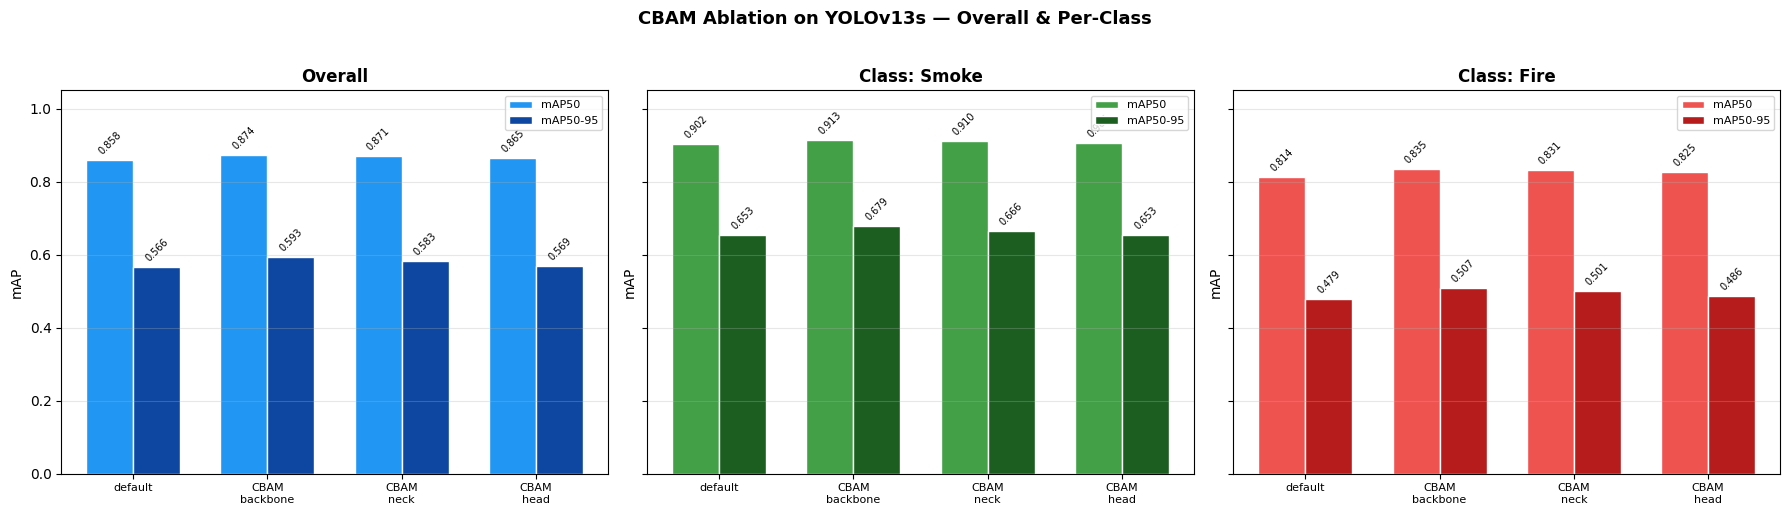

Saved: /content/drive/MyDrive/Project/Fire And Smoke/runs/fire-smoke-cbam_ablation_perclass.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

names  = list(results.keys())
labels = [n.replace("cbam-", "CBAM\n") for n in names]
errs   = [n for n in names if "error" in results[n]]

if not errs:
    CLASS_NAMES = ["Smoke", "Fire"]
    COLORS = {
        "overall": ("#2196F3", "#0D47A1"),
        "Smoke":   ("#43A047", "#1B5E20"),
        "Fire":    ("#EF5350", "#B71C1C"),
    }

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    fig.suptitle("CBAM Ablation on YOLOv13s — Overall & Per-Class",
                 fontsize=13, fontweight="bold", y=1.02)

    x, w = np.arange(len(names)), 0.35

    def draw_bars(ax, vals50, vals95, title, colors):
        b1 = ax.bar(x - w/2, vals50, w, label="mAP50",    color=colors[0], edgecolor="white")
        b2 = ax.bar(x + w/2, vals95, w, label="mAP50-95", color=colors[1], edgecolor="white")
        ax.set_title(title, fontweight="bold")
        ax.set_ylabel("mAP")
        ax.set_ylim(0, 1.05)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8)
        ax.legend(fontsize=8)
        ax.grid(axis="y", alpha=0.3)
        for bar in list(b1) + list(b2):
            h = bar.get_height()
            if h > 0:
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                        f"{h:.3f}", ha="center", va="bottom", fontsize=7, rotation=45)

    # Panel 1: Overall
    draw_bars(axes[0],
              [results[n].get("mAP50", 0)    for n in names],
              [results[n].get("mAP50-95", 0) for n in names],
              "Overall", COLORS["overall"])

    # Panel 2 & 3: Per-class
    for ax, cls in zip(axes[1:], CLASS_NAMES):
        draw_bars(ax,
                  [results[n].get("per_class", {}).get(cls, {}).get("mAP50", 0)    for n in names],
                  [results[n].get("per_class", {}).get(cls, {}).get("mAP50-95", 0) for n in names],
                  f"Class: {cls}", COLORS[cls])

    plt.tight_layout()
    out = os.path.join(BASE_DIR, f"{DATASET_NAME}-cbam_ablation_perclass.png")
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")

else:
    print(f"Errors: {errs}")